### Generate a corgisim scene with a CPGS file

This notebook generates FITS files provided a CPGS file. Here we assume we are simulating an RDI sequence of a target with a companion planet.
The CPGS file must include one of the standard sat spot sequences.

In [1]:
from corgisim import observation
import os
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [2]:
# Copy the Roman CGI prescription file to working folder (or skip if file is already present)
import roman_preflight_proper
roman_preflight_proper.copy_here()

In [ ]:
script_dir = os.getcwd()
# Set path to CPGS file
file = "../HLC_B1_C3_905_ManualEXCAM_defaultSatSpots.xml"

# Set output file path
outpath = "../simulated_data/"
outdir = os.path.join(outpath, 'corgisim/testdata/cpgs')    

Define parameters to inject a companion into the simulated observing scenario.

In [4]:
# Set some companion parameters
planet = [{
    'Vmag': 20.75,                # Vmag of companion
    'magtype': 'vegamag',     
    'position_x': 3.245 * 49.3,    # mas (3.24 * lambda/D)
    'position_y': -3.245 * 49.3,   # mas (3.24 * lambda/D)
}]

### Simulate observation scenario from a CPGS file
This function completes all the required steps to simulate a `corgisim` scene from a CPGS file. 
- `save_as_fits` : If True, writes FITS files to output_dir
- `save_as_list` : Boolean to define whether to save the image files to a list. Set to `False` to conserve memory (otherwise, this may crash)
- `loc_x`, `loc_y` :  The horizontal and vertical coordinates (in pixels) of the center where the sub_frame will be inserted, needed when full_frame=True, and image from CorgiOptics has size is smaller than 1024×1024
- `point_source_info` : Dictionary of companion parameters to inject into the RDI target scene

In [ ]:
# Simulate with CPGS input
observation.generate_observation_scenario_from_cpgs(file, save_as_fits=True, save_as_list=False, output_dim=121, loc_x=300, loc_y=300,
                                                    fast_gain_mode=True, gain_CIC_Q=0.0, point_source_info=planet, full_frame=True,
                                                    output_dir=outdir)


Falling back to blackbody with T=6045.0K
CorgiOptics initialized with proper keywords.
Falling back to blackbody with T=6045.0K
Adding 1 off-axis sources
Saved FITS file to: /Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/corgisim/testdata/cpgs/V0200001001001001001/cgi_0200001001001001001_20261105t1134060_l1_.fits
Saved FITS file to: /Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/corgisim/testdata/cpgs/V0200001001001001001/cgi_0200001001001001001_20261105t1134170_l1_.fits
Saved FITS file to: /Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/corgisim/testdata/cpgs/V0200001001001001001/cgi_0200001001001001001_20261105t1134280_l1_.fits
Saved FITS file to: /Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/corgisim/testdata/cpgs/V0200001001001001001/cgi_0200001001001001001_20261105t1134390_l1_.fits
Saved FITS file to: /Users/shasler/Documents/Research/Projects/Rom

#### What does the L1 data look like?

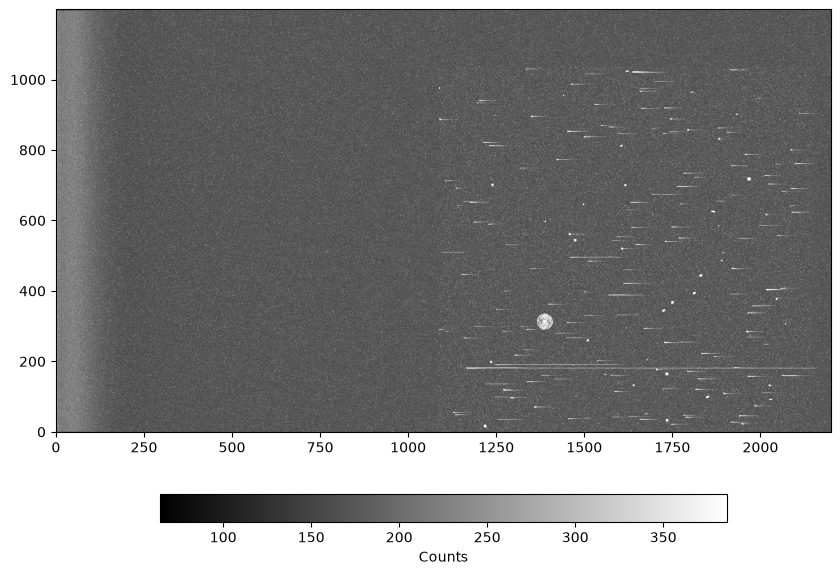

In [ ]:
# Read in one of the saved FITS files and plot it
fits_file = os.path.join(outdir, "V0200001001001001001/cgi_0200001001001001001_20261105t0950080_l1_.fits")
image_data = fits.getdata(fits_file)

plt.figure(figsize=(10, 8))
plt.imshow(image_data, origin='lower', cmap='gray', vmin=np.percentile(image_data, 0), vmax=np.percentile(image_data, 99)) 
# Make the colorbar horizontal and place it above the plot
plt.colorbar(orientation='horizontal', fraction=0.046, pad=0.1, location='bottom', label="Counts") ;